# 04-05 - FP-Growth dan Association Rules

Task 4 dan Task 5 menggunakan algoritma FP-Growth.

- **Input** = `data/author_transactions.parquet` (hasil Task 3, sama dengan input Apriori).
- **Minimum support** = 0,1%, 0,5%, 1%, dan 2%.
- **Minimum confidence** = 50%.

In [1]:
import json
import sys
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
sys.path.insert(0 , str(Path.cwd().parent))
from src import config
from src.apriori import SUPPORT_LEVELS
from src.viz import SERIES , TEXT_MUTED , apply_style , save
from src.fp_growth import is_pair_rule , readable , run_experiments , venue_names

In [2]:
apply_style()
names = venue_names()

def show_rules(rules) :
    view = rules.assign(antecedent = [readable(text , names) for (text) in (rules["antecedent"])] , consequent = [readable(text , names) for (text) in (rules["consequent"])])
    return view[["antecedent" , "consequent" , "support_count" , "support_pct" , "confidence_pct" , "lift"]].round(4)

summary = run_experiments()

Support 0.1%: 1462 itemset, 1225 rules
Support 0.5%: 77 itemset, 7 rules
Support 1%: 29 itemset, 1 rules
Support 2%: 5 itemset, 0 rules


## 1. Metode

- **Scan 1** = hitung support count setiap venue, buang venue yang tidak frequent, lalu urutkan menurun menjadi list $L$.
- **Scan 2** = sisipkan venue frequent pada setiap transaksi (urut sesuai $L$) ke FP-tree.
  - Transaksi dengan prefix yang sama berbagi node, sehingga count node bertambah.
  - Header table menghubungkan semua node dengan venue yang sama (node-link).
- **Mining** = dimulai dari venue paling jarang.
  - Ambil conditional pattern base, yaitu prefix path menuju venue tersebut.
  - Bangun conditional FP-tree, lalu ulangi secara rekursif.
  - Jika tree hanya berupa satu path, semua kombinasi node pada path langsung menjadi pola.
- **Minimum support count** = memakai `minimum_count` dari `src/apriori.py`, sehingga ambangnya sama dengan Apriori.

In [3]:
display(summary.drop(columns = "elapsed_seconds"))

,min_support_pct,min_support_count,n_transactions,n_frequent_itemsets,n_frequent_1,n_frequent_2,n_frequent_3,n_frequent_4plus,max_itemset_size,n_rules_confidence_50pct
0,0.1,1818,1817265,1462,582,386,322,172,6,1225
1,0.5,9087,1817265,77,60,16,1,0,3,7
2,1,18173,1817265,29,28,1,0,0,2,1
3,2,36346,1817265,5,5,0,0,0,1,0


## 2. Frequent Itemsets

Jumlah frequent itemsets per ukuran untuk setiap minimum support. Skala sumbu y tiap panel berbeda.

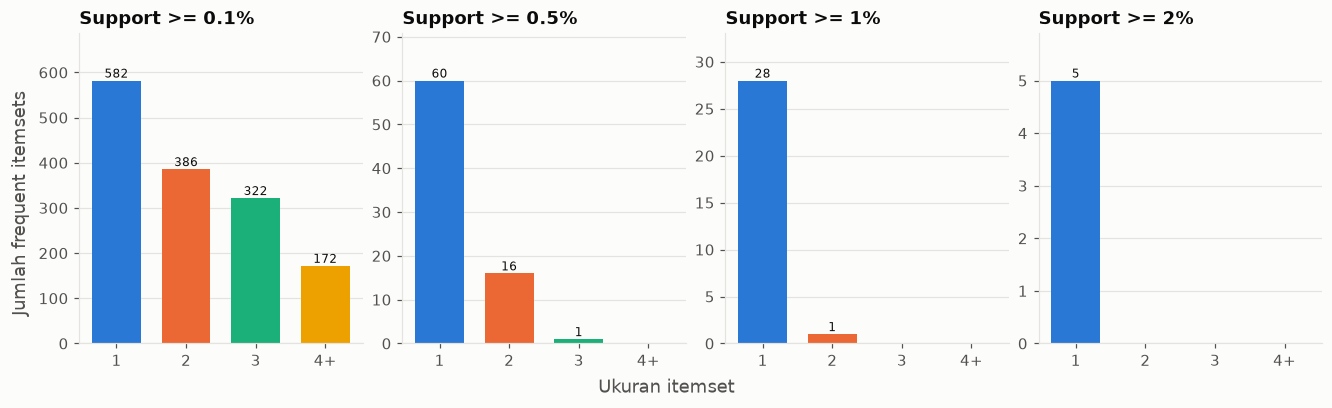

In [4]:
fig , axes = plt.subplots(1 , 4 , figsize = (12 , 3.6) , layout = "constrained")
labels = ["1" , "2" , "3" , "4+"]
columns = ["n_frequent_1" , "n_frequent_2" , "n_frequent_3" , "n_frequent_4plus"]
for (ax , row) in (zip(axes , summary.itertuples(index = False))) :
    values = [getattr(row , column) for (column) in (columns)]
    ax.bar(labels , values , color = SERIES[: 4] , width = 0.7)
    ax.set_title(f"Support >= {row.min_support_pct}%")
    ax.set_ylim(0 , max(values) * 1.18 if (max(values)) else 1)
    for (x , count) in (enumerate(values)) :
        if (count) :
            ax.text(x , count , str(count) , ha = "center" , va = "bottom" , fontsize = 8)
    ax.grid(axis = "x" , visible = False)
fig.supylabel("Jumlah frequent itemsets" , color = TEXT_MUTED)
fig.supxlabel("Ukuran itemset" , color = TEXT_MUTED)
save(fig , "04_fpgrowth_itemset_counts")
plt.show()

### Top 10 Itemsets per Minimum Support

In [5]:
for (support_pct) in (SUPPORT_LEVELS) :
    table = pd.read_csv(config.TABLES_DIR / f"fpgrowth_top10_itemsets_{support_pct.replace('.' , 'p')}pct.csv")
    table.insert(1 , "venue" , [readable(text , names) for (text) in (table["itemset"])])
    print(f"Minimum support {support_pct}%")
    display(table[["itemset" , "venue" , "size" , "support_count" , "support_pct"]])

Minimum support 0.1%


,itemset,venue,size,support_count,support_pct
0,"[""nips""]",NeurIPS,1,57358,3.156282
1,"[""aaai""]",AAAI,1,44683,2.458805
2,"[""icassp""]",ICASSP,1,41063,2.259604
3,"[""embc""]",EMBC,1,39311,2.163196
4,"[""hci""]",HCI,1,37845,2.082525
5,"[""igarss""]",IGARSS,1,35207,1.937362
6,"[""cvpr""]",CVPR,1,34940,1.922670
7,"[""emnlp""]",EMNLP,1,33355,1.835451
8,"[""icml""]",ICML,1,31659,1.742123
9,"[""iros""]",IROS,1,31178,1.715655


Minimum support 0.5%


,itemset,venue,size,support_count,support_pct
0,"[""nips""]",NeurIPS,1,57358,3.156282
1,"[""aaai""]",AAAI,1,44683,2.458805
2,"[""icassp""]",ICASSP,1,41063,2.259604
3,"[""embc""]",EMBC,1,39311,2.163196
4,"[""hci""]",HCI,1,37845,2.082525
5,"[""igarss""]",IGARSS,1,35207,1.937362
6,"[""cvpr""]",CVPR,1,34940,1.922670
7,"[""emnlp""]",EMNLP,1,33355,1.835451
8,"[""icml""]",ICML,1,31659,1.742123
9,"[""iros""]",IROS,1,31178,1.715655


Minimum support 1%


,itemset,venue,size,support_count,support_pct
0,"[""nips""]",NeurIPS,1,57358,3.156282
1,"[""aaai""]",AAAI,1,44683,2.458805
2,"[""icassp""]",ICASSP,1,41063,2.259604
3,"[""embc""]",EMBC,1,39311,2.163196
4,"[""hci""]",HCI,1,37845,2.082525
5,"[""igarss""]",IGARSS,1,35207,1.937362
6,"[""cvpr""]",CVPR,1,34940,1.922670
7,"[""emnlp""]",EMNLP,1,33355,1.835451
8,"[""icml""]",ICML,1,31659,1.742123
9,"[""iros""]",IROS,1,31178,1.715655


Minimum support 2%


,itemset,venue,size,support_count,support_pct
0,"[""nips""]",NeurIPS,1,57358,3.156282
1,"[""aaai""]",AAAI,1,44683,2.458805
2,"[""icassp""]",ICASSP,1,41063,2.259604
3,"[""embc""]",EMBC,1,39311,2.163196
4,"[""hci""]",HCI,1,37845,2.082525


### Frequent 1-Itemsets, 2-Itemsets, dan 3-Itemsets

Ditampilkan pada support 0,1% karena hanya ambang ini yang masih memiliki 3-itemset. Pasangan dan tripel adalah kombinasi venue yang paling sering muncul bersama.

Top 10 1-itemset pada support 0,1%


,itemset,venue,support_count,support_pct
0,"[""nips""]",NeurIPS,57358,3.156282
1,"[""aaai""]",AAAI,44683,2.458805
2,"[""icassp""]",ICASSP,41063,2.259604
3,"[""embc""]",EMBC,39311,2.163196
4,"[""hci""]",HCI,37845,2.082525
5,"[""igarss""]",IGARSS,35207,1.937362
6,"[""cvpr""]",CVPR,34940,1.922670
7,"[""emnlp""]",EMNLP,33355,1.835451
8,"[""icml""]",ICML,31659,1.742123
9,"[""iros""]",IROS,31178,1.715655


Top 10 2-itemset pada support 0,1%


,itemset,venue,support_count,support_pct
0,"[""icml"", ""nips""]","ICML, NeurIPS",18423,1.013776
1,"[""iclr"", ""nips""]","ICLR, NeurIPS",17514,0.963756
2,"[""aaai"", ""nips""]","AAAI, NeurIPS",15761,0.867292
3,"[""acl"", ""emnlp""]","ACL, EMNLP",14397,0.792234
4,"[""cvpr"", ""nips""]","CVPR, NeurIPS",14138,0.777982
5,"[""cvpr"", ""iccv""]","CVPR, ICCV",13601,0.748432
6,"[""iclr"", ""icml""]","ICLR, ICML",12713,0.699568
7,"[""icra"", ""iros""]","ICRA, IROS",11859,0.652574
8,"[""cvpr"", ""eccv""]","CVPR, ECCV",11087,0.610093
9,"[""aaai"", ""ijcai""]","AAAI, IJCAI",11020,0.606406


Top 10 3-itemset pada support 0,1%


,itemset,venue,support_count,support_pct
0,"[""iclr"", ""icml"", ""nips""]","ICLR, ICML, NeurIPS",10273,0.565300
1,"[""cvpr"", ""iccv"", ""nips""]","CVPR, ICCV, NeurIPS",7859,0.432463
2,"[""aaai"", ""icml"", ""nips""]","AAAI, ICML, NeurIPS",7516,0.413589
3,"[""cvpr"", ""eccv"", ""iccv""]","CVPR, ECCV, ICCV",7426,0.408636
4,"[""aaai"", ""iclr"", ""nips""]","AAAI, ICLR, NeurIPS",7217,0.397135
5,"[""aaai"", ""cvpr"", ""nips""]","AAAI, CVPR, NeurIPS",6811,0.374794
6,"[""cvpr"", ""iclr"", ""nips""]","CVPR, ICLR, NeurIPS",6641,0.365439
7,"[""cvpr"", ""eccv"", ""nips""]","CVPR, ECCV, NeurIPS",6526,0.359111
8,"[""aaai"", ""cvpr"", ""iccv""]","AAAI, CVPR, ICCV",6041,0.332423
9,"[""acl"", ""emnlp"", ""naacl""]","ACL, EMNLP, NAACL-HLT",5957,0.327800


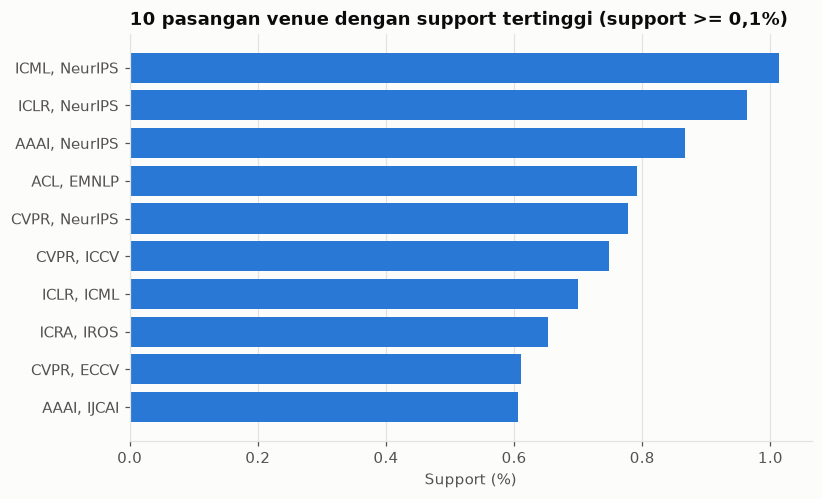

In [6]:
for (name , title) in (("singletons" , "1-itemset") , ("pairs" , "2-itemset") , ("triples" , "3-itemset")) :
    table = pd.read_csv(config.TABLES_DIR / f"fpgrowth_top10_{name}_0p1pct.csv")
    table.insert(1 , "venue" , [readable(text , names) for (text) in (table["itemset"])])
    print(f"Top 10 {title} pada support 0,1%")
    display(table[["itemset" , "venue" , "support_count" , "support_pct"]])
pairs = pd.read_csv(config.TABLES_DIR / "fpgrowth_top10_pairs_0p1pct.csv")
fig , ax = plt.subplots(figsize = (8 , 4.8))
ax.barh([readable(text , names) for (text) in (pairs["itemset"])][:: -1] , pairs["support_pct"].iloc[:: -1] , color = SERIES[0])
ax.set_xlabel("Support (%)")
ax.set_title("10 pasangan venue dengan support tertinggi (support >= 0,1%)")
ax.grid(axis = "y" , visible = False)
save(fig , "04_fpgrowth_top_pairs")
plt.show()

## 3. Association Rules

- **Pembentukan rule** = untuk setiap frequent itemset $l$ dan subset $s$, rule $s \rightarrow (l - s)$ disimpan jika confidence ≥ 50%.
- **Support** = count(A ∪ B) / N.
- **Confidence** = count(A ∪ B) / count(A).
- **Lift** = confidence / support(B).

### Top 10 Rules dengan Lift Tertinggi

In [7]:
for (row) in (summary.itertuples(index = False)) :
    rules = pd.read_csv(config.TABLES_DIR / f"fpgrowth_top10_lift_{row.min_support_pct.replace('.' , 'p')}pct.csv")
    print(f"Minimum support {row.min_support_pct}%: {row.n_rules_confidence_50pct} rules")
    if (not rules.empty) :
        display(show_rules(rules))

Minimum support 0.1%: 1225 rules


,antecedent,consequent,support_count,support_pct,confidence_pct,lift
0,"ICLR, NAACL-HLT","ACL, EMNLP, NeurIPS",1885,0.1037,51.0287,155.7224
1,"CVPR, ECCV, ICML","ICCV, ICLR",1832,0.1008,55.2973,153.7012
2,"AAAI, ECCV, ICLR","CVPR, ICCV, NeurIPS",1865,0.1026,65.7385,152.0094
3,"EMNLP, NAACL-HLT, NeurIPS","ACL, ICLR",1885,0.1037,54.4955,149.6642
4,"AAAI, ICCV, ICLR","CVPR, ECCV, NeurIPS",1865,0.1026,53.2857,148.3823
5,"ECCV, ICML, NeurIPS","ICCV, ICLR",1838,0.1011,52.8617,146.9312
6,"ACL, NAACL-HLT, NeurIPS","EMNLP, ICLR",1885,0.1037,56.6576,144.0632
7,"AAAI, CVPR, ICCV, ICLR","ECCV, NeurIPS",1865,0.1026,64.5999,141.2188
8,"AAAI, CVPR, ECCV, NeurIPS","ICCV, ICLR",1865,0.1026,50.7898,141.1723
9,"ECCV, ICCV, ICML","CVPR, ICLR",1832,0.1008,65.4987,137.5099


Minimum support 0.5%: 7 rules


,antecedent,consequent,support_count,support_pct,confidence_pct,lift
0,"ICML, NeurIPS",ICLR,10273,0.5653,55.7618,33.9568
1,"ICLR, NeurIPS",ICML,10273,0.5653,58.6559,33.6692
2,ECCV,CVPR,11087,0.6101,61.0787,31.7676
3,ICCV,CVPR,13601,0.7484,56.4427,29.3564
4,"ICLR, ICML",NeurIPS,10273,0.5653,80.8070,25.6020
5,ICLR,NeurIPS,17514,0.9638,58.6891,18.5944
6,ICML,NeurIPS,18423,1.0138,58.1920,18.4369


Minimum support 1%: 1 rules


,antecedent,consequent,support_count,support_pct,confidence_pct,lift
0,ICML,NeurIPS,18423,1.0138,58.192,18.4369


Minimum support 2%: 0 rules


### Rule Satu Venue ke Satu Venue

Seluruh rule pada support 0,1% yang antecedent dan consequent-nya hanya satu venue, agar hubungan antarvenue lebih mudah dibaca.

,antecedent,consequent,support_count,support_pct,confidence_pct,lift
139,ECOC,OFC,4528,0.2492,66.4709,79.9439
149,ASRU,INTERSPEECH,1961,0.1079,72.7644,74.2002
671,EACL,ACL,2832,0.1558,60.2553,37.2994
680,CoRL,ICRA,2084,0.1147,58.1473,37.0340
732,Conference on Designing Interactive Systems,CHI,3163,0.1741,55.7848,34.2289
750,EACL,EMNLP,2894,0.1593,61.5745,33.5473
768,NAACL-HLT,ACL,7453,0.4101,53.2966,32.9918
785,3DV,CVPR,1850,0.1018,61.7490,32.1163
794,ECCV,CVPR,11087,0.6101,61.0787,31.7676
797,IJCNLP,ACL,1840,0.1013,51.0686,31.6126


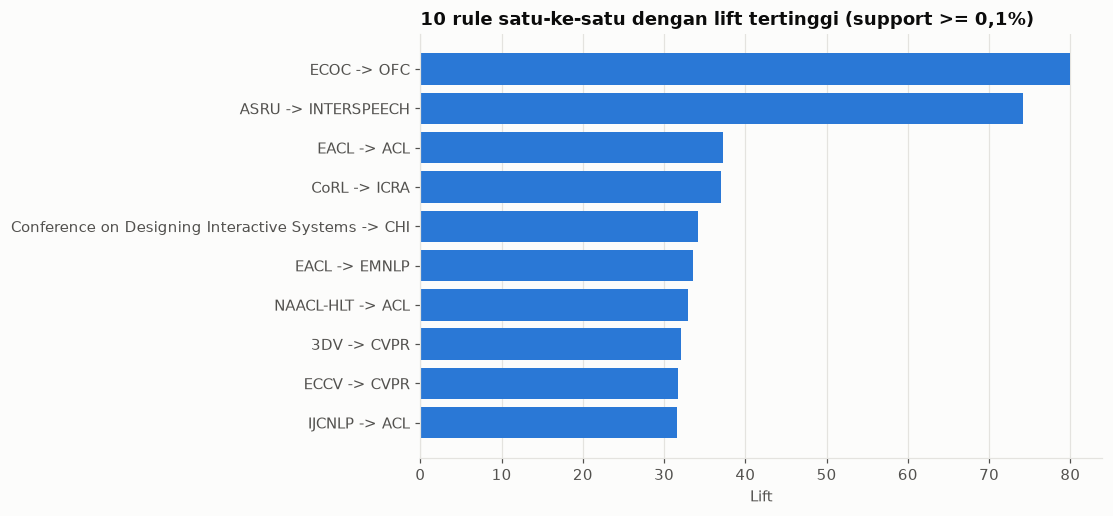

In [8]:
rules = pd.read_csv(config.EXPERIMENTS_DIR / "fpgrowth_rules_0p1pct.csv")
pair_rules = rules[is_pair_rule(rules)]
display(show_rules(pair_rules))
top_pairs = pair_rules.head(10)
fig , ax = plt.subplots(figsize = (8 , 5))
ax.barh([readable(a , names) + " -> " + readable(c , names) for (a , c) in (zip(top_pairs["antecedent"] , top_pairs["consequent"]))][:: -1] , top_pairs["lift"].iloc[:: -1] , color = SERIES[0])
ax.set_xlabel("Lift")
ax.set_title("10 rule satu-ke-satu dengan lift tertinggi (support >= 0,1%)")
ax.grid(axis = "y" , visible = False)
save(fig , "05_fpgrowth_pair_rule_lift")
plt.show()

### Support Tinggi vs Lift Tinggi

- Lift = confidence / P(B), sehingga venue consequent yang populer cenderung menurunkan lift.
- Tabel menampilkan support (%) venue antecedent dan consequent pada setiap rule satu-ke-satu.

,antecedent,consequent,support_count,support_pct,confidence_pct,lift,antecedent_support_pct,consequent_support_pct
1187,ICLR,NeurIPS,17514,0.9638,58.6891,18.5944,1.642,3.156
1178,AISTATS,NeurIPS,5223,0.2874,61.0663,19.3475,0.471,3.156
1192,ICML,NeurIPS,18423,1.0138,58.1920,18.4369,1.742,3.156
1202,UAI,NeurIPS,2638,0.1452,56.2713,17.8284,0.258,3.156
794,ECCV,CVPR,11087,0.6101,61.0787,31.7676,0.999,1.923
785,3DV,CVPR,1850,0.1018,61.7490,32.1163,0.165,1.923
856,ICCV,CVPR,13601,0.7484,56.4427,29.3564,1.326,1.923
812,NAACL-HLT,EMNLP,7952,0.4376,56.8650,30.9815,0.770,1.835
890,IJCNLP,EMNLP,1871,0.1030,51.9289,28.2922,0.198,1.835
750,EACL,EMNLP,2894,0.1593,61.5745,33.5473,0.259,1.835


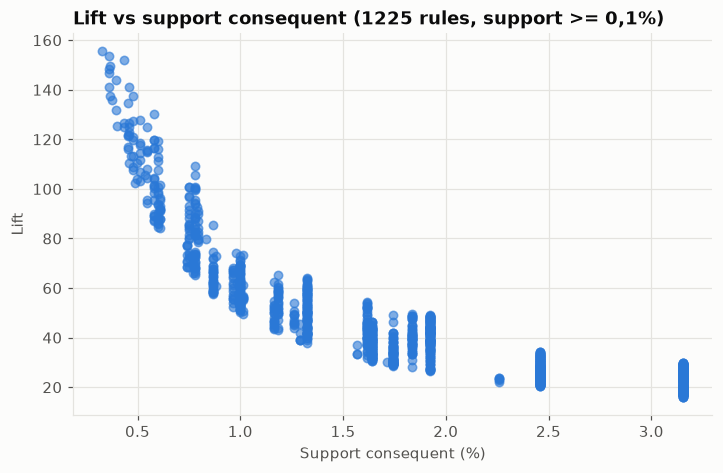

In [9]:
itemsets = pd.read_csv(config.EXPERIMENTS_DIR / "fpgrowth_itemsets_0p1pct.csv")
support_of = dict(zip(itemsets["itemset"] , itemsets["support_pct"]))
display(show_rules(pair_rules).assign(antecedent_support_pct = pair_rules["antecedent"].map(support_of).round(3).to_numpy() , consequent_support_pct = pair_rules["consequent"].map(support_of).round(3).to_numpy()).sort_values("consequent_support_pct" , ascending = False))
fig , ax = plt.subplots(figsize = (7.5 , 4.5))
ax.scatter(rules["consequent"].map(support_of) , rules["lift"] , s = 30 , color = SERIES[0] , alpha = 0.6)
ax.set_xlabel("Support consequent (%)")
ax.set_ylabel("Lift")
ax.set_title(f"Lift vs support consequent ({len(rules)} rules, support >= 0,1%)")
save(fig , "05_fpgrowth_lift_vs_support")
plt.show()

### Perbedaan Support, Confidence, dan Lift

Contoh rule ICML → NeurIPS (support 0,1%):

- **Support** = 1,014%, artinya 1,014% dari seluruh penulis pernah publikasi di ICML dan NeurIPS. Support menunjukkan seberapa umum pola, tanpa arah.
- **Confidence** = 58,19%, artinya dari penulis yang publikasi di ICML, 58,19% juga publikasi di NeurIPS. Confidence berarah, sehingga ICML → NeurIPS dapat berbeda dengan NeurIPS → ICML.
- **Lift** = 18,44, artinya peluang tersebut 18,44 kali lebih besar daripada peluang dasar penulis publikasi di NeurIPS.
  - Lift > 1 = korelasi positif.
  - Lift = 1 = independen.
  - Lift < 1 = korelasi negatif.

### Interpretasi

Frequent itemsets dan rules FP-Growth sama persis dengan hasil Apriori (dibuktikan pada `06_performance_comparison.ipynb`), sehingga angka di bawah berlaku untuk kedua algoritma.

- **Frequent itemsets**:
  - Support 0,1% = 1.462 itemset (582 venue tunggal, 386 pasangan, 322 tripel, dan 172 itemset berukuran ≥ 4).
  - Pasangan terbanyak = ICML–NeurIPS (1,014% penulis), diikuti ICLR–NeurIPS, AAAI–NeurIPS, ACL–EMNLP, CVPR–NeurIPS, dan CVPR–ICCV.
  - Tripel terbanyak = ICLR–ICML–NeurIPS (0,565%).
- **Pengaruh minimum support**:
  - Jumlah itemset turun dari 1.462 (0,1%) menjadi 77 (0,5%), 29 (1%), dan 5 (2%).
  - Hal ini terjadi karena minimum support adalah ambang pemangkasan, dan 58,21% penulis hanya memiliki satu venue, sehingga support kombinasi venue jauh lebih kecil daripada support venue tunggal.
- **Rules**:
  - Jumlah rules = 1.225 (0,1%), 7 (0,5%), 1 (1%, yaitu ICML → NeurIPS), dan 0 (2%).
  - Semua rules memiliki lift > 1 (minimum ±15,9), artinya semua hubungan yang lolos berkorelasi positif.
  - Lift tertinggi = ICLR, NAACL → ACL, EMNLP, NeurIPS (lift 155,7), tetapi support-nya hanya 0,104%, dekat dengan ambang minimum.
- **Support tinggi tidak selalu menghasilkan lift tinggi**:
  - ICML → NeurIPS memiliki support terbesar (1,014%), tetapi lift-nya hanya 18,44 (peringkat 1.193 dari 1.225 rules).
  - Rule satu-ke-satu dengan consequent NeurIPS (venue terpopuler, support 3,156%) memiliki lift terendah (17,8–19,3).
  - Sebaliknya, ECOC → OFC (support 0,249%) memiliki lift 79,9 karena OFC hanya didatangi 0,831% penulis.
  - Sehingga dapat disimpulkan bahwa venue yang populer justru cenderung menghasilkan lift yang lebih rendah.
- **Hubungan paling menarik**:
  - ECOC → OFC (confidence 66,5%, lift 79,9) dan ASRU → INTERSPEECH (confidence 72,8%, lift 74,2), yaitu venue kecil yang penulisnya sangat terikat dengan venue besar di bidang yang sama.
  - ICML → NeurIPS adalah hubungan yang paling umum (support 1,014%).
- **Pola publikasi antar-konferensi**:
  - Terdapat 18 rule satu-ke-satu, dan seluruhnya menghubungkan venue dalam bidang yang sama, yaitu NLP (EACL, NAACL-HLT, IJCNLP → ACL / EMNLP), machine learning (AISTATS, ICLR, ICML, UAI → NeurIPS / ICML), computer vision (3DV, ECCV, ICCV → CVPR), robotika (CoRL → ICRA), HCI (DIS → CHI), speech (ASRU → INTERSPEECH), dan komunikasi optik (ECOC → OFC).
  - Arah rule selalu dari venue yang lebih kecil ke venue yang lebih besar.
  - Hubungan lintas bidang hanya muncul pada rule dengan beberapa venue, misalnya CVPR, ICCV → NeurIPS (support 0,43%, confidence 57,8%, lift 18,3).
  - Sehingga dapat disimpulkan bahwa penulis cenderung publikasi di venue dalam satu bidang yang sama.
- Rule hanya menunjukkan venue yang muncul bersama dalam riwayat penulis 2015–2025, bukan urutan waktu maupun sebab-akibat.